# Amazon Review Sentiment Analysis

Author: Lucy Giang (Jul. 2026)

This notebook trains a binary classifier to identify negative and positive Amazon reviews using the Amazon Reviews Polarity dataset from Kaggle. The source labels are polarity 1 (negative) and 2 (positive); neutral reviews are excluded.

We download and inspect the files, prepare review text and labels, train a TF-IDF + logistic regression model, evaluate on the provided test split, and predict sentiment for new examples. Because the corpus contains millions of rows, the default training sample is limited for practical runtime and memory. Increase it or set it to None when resources allow.

Dataset: [Amazon Reviews on Kaggle](https://www.kaggle.com/datasets/kritanjalijain/amazon-reviews). This polarity corpus is described in Zhang, Zhao, and LeCun (2015), [Character-level Convolutional Networks for Text Classification](https://arxiv.org/abs/1509.01626).

## 1. Install and import dependencies

Install the required packages in this notebook environment if needed. Kaggle authentication may be required to download the dataset.

In [13]:
# Install once from the project directory with: python -m pip install -r requirements.txt

import gc
import time
from pathlib import Path

import joblib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 160)

## 2. Download and locate the dataset

The dataset download returns a versioned cache directory. We search recursively for train.csv and test.csv to avoid depending on a specific cache path. (Another option is downloading the dataset directly.)

In [14]:
# Reuse a local KaggleHub cache when present so reruns do not require a network call.
cache_root = Path.home() / '.cache' / 'kagglehub' / 'datasets' / 'kritanjalijain' / 'amazon-reviews' / 'versions'
cached_versions = sorted(
    (path for path in cache_root.iterdir() if path.is_dir()
     and (path / 'train.csv').exists() and (path / 'test.csv').exists()),
    key=lambda path: int(path.name) if path.name.isdigit() else -1,
) if cache_root.exists() else []
if cached_versions:
    dataset_path = cached_versions[-1]
    print('Using cached KaggleHub dataset version:', dataset_path.name)
else:
    dataset_path = Path(kagglehub.dataset_download('kritanjalijain/amazon-reviews'))
#print('Path to dataset files:', dataset_path)
csv_files = list(dataset_path.rglob('*.csv'))
print('CSV files found:', [p.name for p in csv_files])

def find_split(split_name):
    matches = [p for p in csv_files if p.stem.lower() == split_name]
    if not matches:
        raise FileNotFoundError(f'Could not find {split_name}.csv under {dataset_path}; found {csv_files}')
    return matches[0]

train_path = find_split('train')
test_path = find_split('test')
#print('Train file:', train_path)
#print('Test file:', test_path)

Using cached KaggleHub dataset version: 2
CSV files found: ['test.csv', 'train.csv']


## 3. Load and validate records

The expected columns are polarity, title, and text. Some copies have a header and others do not. The loader handles both formats, removes invalid labels and empty reviews, combines title and body, and maps the source labels to readable binary targets.

In [15]:
COLUMN_NAMES = ['polarity', 'title', 'text']

def load_reviews(path):
    frame = pd.read_csv(path, header=None, names=COLUMN_NAMES, dtype='string',
                        keep_default_na=False, encoding='utf-8', on_bad_lines='error')
    if len(frame) and frame.iloc[0]['polarity'].strip().lower() in {'polarity', 'label', 'sentiment'}:
        frame = frame.iloc[1:].copy()
    frame['polarity'] = pd.to_numeric(frame['polarity'], errors='coerce')
    frame = frame[frame['polarity'].isin([1, 2])].copy()
    frame['title'] = frame['title'].fillna('').astype(str).str.strip()
    frame['text'] = frame['text'].fillna('').astype(str).str.strip()
    frame['review'] = (frame['title'] + ' ' + frame['text']).str.strip()
    frame = frame[frame['review'].ne('')].copy()
    frame['sentiment'] = frame['polarity'].map({1: 'negative', 2: 'positive'})
    frame['label'] = frame['polarity'].map({1: 0, 2: 1}).astype('int8')
    return frame[['review', 'sentiment', 'label']]

train_df = load_reviews(train_path)
test_df = load_reviews(test_path)
print(f'Train rows: {len(train_df):,} | Test rows: {len(test_df):,}')
display(train_df.head())
display(train_df['sentiment'].value_counts().rename('count').to_frame())

Train rows: 3,600,000 | Test rows: 400,000


,review,sentiment,label
0,Stuning even for the non-gamer This sound track was beautiful! It paints the senery in your mind so well I would recomend it even to people who hate vid. ga...,positive,1
1,The best soundtrack ever to anything. I'm reading a lot of reviews saying that this is the best 'game soundtrack' and I figured that I'd write a review to d...,positive,1
2,"Amazing! This soundtrack is my favorite music of all time, hands down. The intense sadness of ""Prisoners of Fate"" (which means all the more if you've played...",positive,1
3,Excellent Soundtrack I truly like this soundtrack and I enjoy video game music. I have played this game and most of the music on here I enjoy and it's truly...,positive,1
4,"Remember, Pull Your Jaw Off The Floor After Hearing it If you've played the game, you know how divine the music is! Every single song tells a story of the g...",positive,1


,count
sentiment,
positive,1800000
negative,1800000


## 4. Explore class balance and review lengths

These plots check whether sentiment classes are balanced and show the distribution of review lengths. We use a sample for plotting to keep visualization responsive.

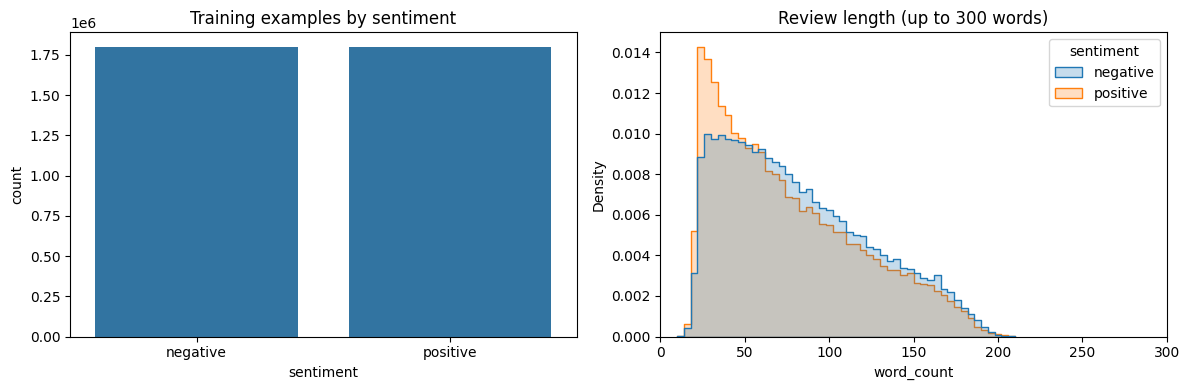

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x='sentiment', order=['negative', 'positive'], ax=axes[0])
axes[0].set_title('Training examples by sentiment')
train_df['word_count'] = train_df['review'].str.split().str.len()
plot_df = train_df.sample(min(100_000, len(train_df)), random_state=RANDOM_STATE)
sns.histplot(data=plot_df, x='word_count', hue='sentiment', bins=50, stat='density',
             common_norm=False, element='step', ax=axes[1])
axes[1].set_xlim(0, 300)
axes[1].set_title('Review length (up to 300 words)')
plt.tight_layout()
plt.show()
train_df = train_df.drop(columns='word_count')

## 5. Create reproducible training and test samples

The source contains millions of records. To keep this project runnable on a laptop, the final fit uses a reproducible, class-balanced sample and evaluation uses a sample from the official held-out test split. We will separately use stratified cross-validation on a smaller training-only subset to compare model choices. The official test split is never used to select hyperparameters. Set either sample-size constant to None to use the complete split when resources allow.

In [18]:
TRAIN_SAMPLE_SIZE = 100_000
TEST_SAMPLE_SIZE = 50_000

def ensure_label_column(frame, split_name):
    # Recover the target if an older preparation cell created this dataframe.
    if 'label' not in frame.columns:
        if 'polarity' in frame.columns:
            frame = frame.copy()
            frame['label'] = pd.to_numeric(frame['polarity'], errors='coerce').map({1: 0, 2: 1})
        elif 'sentiment' in frame.columns:
            frame = frame.copy()
            frame['label'] = frame['sentiment'].map({'negative': 0, 'positive': 1})
        else:
            raise KeyError(f"{split_name} data has no 'label' column. Available columns: {list(frame.columns)}. Rerun the 'Load and validate records' cell, then rerun this cell.")
    if frame['label'].isna().any():
        raise ValueError(f"{split_name} data contains missing or unrecognized labels. Rerun the 'Load and validate records' cell.")
    return frame

def balanced_sample(frame, sample_size, seed=RANDOM_STATE):
    frame = ensure_label_column(frame, 'Training')
    if sample_size is None or sample_size >= len(frame):
        return frame.sample(frac=1, random_state=seed).reset_index(drop=True)
    
    labels = frame['label'].unique()
    per_class = max(1, sample_size // len(labels))
    
    # Sample each class separately to ensure the 'label' column is safely retained
    sampled_pieces = []
    for lbl in labels:
        class_group = frame[frame['label'] == lbl]
        n_sample = min(len(class_group), per_class)
        sampled_pieces.append(class_group.sample(n=n_sample, random_state=seed))
        
    sampled = pd.concat(sampled_pieces, ignore_index=True)
    return sampled.sample(frac=1, random_state=seed).reset_index(drop=True)

train_df = ensure_label_column(train_df, 'Training')
test_df = ensure_label_column(test_df, 'Test')
train_sample = balanced_sample(train_df, TRAIN_SAMPLE_SIZE)
test_sample = (test_df.sample(min(TEST_SAMPLE_SIZE, len(test_df)), random_state=RANDOM_STATE)
              if TEST_SAMPLE_SIZE is not None else test_df)

X_train, y_train = train_sample["review"], train_sample["label"]
X_test, y_test = test_sample['review'], test_sample['label']

print(f'Fit rows: {len(X_train):,}; evaluation rows: {len(X_test):,}')
display(train_sample['sentiment'].value_counts(normalize=True).rename('proportion').to_frame())

Fit rows: 100,000; evaluation rows: 50,000


,proportion
sentiment,
negative,0.5
positive,0.5


## 6. Compare baselines with stratified cross-validation

We compare a majority-class DummyClassifier, Multinomial Naive Bayes, a unigram logistic regression baseline (C=1), and a word unigram/bigram logistic regression candidate (C=4). These are explicit candidates, not assumed winners. Three-fold StratifiedKFold preserves class proportions. We measure accuracy, positive-class F1, ROC-AUC, average fit time, and prediction latency per 1,000 validation reviews. Cross-validation sees only training records; the official test split remains untouched until final evaluation.

For runtime, cross-validation uses a balanced subset of at most 20,000 training reviews. The chosen pipeline is the candidate with the highest mean cross-validated F1; the table lets us inspect whether the more expressive model earns its extra cost.

In [19]:
CV_SAMPLE_SIZE = 18_000
CV_FOLDS = 3

cv_df = balanced_sample(train_df, CV_SAMPLE_SIZE)
X_cv = cv_df['review'].reset_index(drop=True)
y_cv = cv_df['label'].reset_index(drop=True)

CANDIDATES = {
    'Dummy majority': {
        'vectorizer': None,
        'classifier': DummyClassifier(strategy='most_frequent'),
    },
    'MultinomialNB + unigram TF-IDF': {
        'vectorizer': {'ngram_range': (1, 1), 'min_df': 2, 'max_features': 200_000},
        'classifier': MultinomialNB(),
    },
    'Logistic regression baseline (unigram, C=1)': {
        'vectorizer': {'ngram_range': (1, 1), 'min_df': 2, 'max_features': 200_000},
        'classifier': LogisticRegression(solver='liblinear', C=1.0, max_iter=300,
                                         random_state=RANDOM_STATE),
    },
    'Logistic regression candidate (1-2 grams, C=4)': {
        'vectorizer': {'ngram_range': (1, 2), 'min_df': 2, 'max_features': 300_000},
        'classifier': LogisticRegression(solver='liblinear', C=4.0, max_iter=300,
                                         random_state=RANDOM_STATE),
    },
}

def build_candidate(name):
    spec = CANDIDATES[name]
    if spec['vectorizer'] is None:
        return Pipeline([('classifier', spec['classifier'])])
    vectorizer_options = spec['vectorizer']
    vectorizer = TfidfVectorizer(lowercase=True, strip_accents='unicode',
                                 sublinear_tf=True, dtype=np.float32, **vectorizer_options)
    return Pipeline([('tfidf', vectorizer), ('classifier', spec['classifier'])])

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for candidate_name in CANDIDATES:
    for fold, (fit_idx, valid_idx) in enumerate(cv.split(X_cv, y_cv), start=1):
        candidate = build_candidate(candidate_name)
        X_fit, X_valid = X_cv.iloc[fit_idx], X_cv.iloc[valid_idx]
        y_fit, y_valid = y_cv.iloc[fit_idx], y_cv.iloc[valid_idx]

        start = time.perf_counter()
        candidate.fit(X_fit, y_fit)
        fit_seconds = time.perf_counter() - start

        start = time.perf_counter()
        valid_pred = candidate.predict(X_valid)
        inference_seconds = time.perf_counter() - start
        if hasattr(candidate, 'predict_proba'):
            valid_score = candidate.predict_proba(X_valid)[:, 1]
        else:
            valid_score = candidate.decision_function(X_valid)

        cv_rows.append({
            'model': candidate_name,
            'fold': fold,
            'accuracy': accuracy_score(y_valid, valid_pred),
            'f1': f1_score(y_valid, valid_pred),
            'roc_auc': roc_auc_score(y_valid, valid_score),
            'fit_seconds': fit_seconds,
            'inference_ms_per_1000': inference_seconds / len(X_valid) * 1000 * 1000,
        })
        del candidate
        gc.collect()

cv_results = pd.DataFrame(cv_rows)
cv_summary = (cv_results.groupby('model')
              .agg(accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'),
                   f1_mean=('f1', 'mean'), f1_std=('f1', 'std'),
                   roc_auc_mean=('roc_auc', 'mean'), fit_seconds_mean=('fit_seconds', 'mean'),
                   inference_ms_per_1000_mean=('inference_ms_per_1000', 'mean'))
              .sort_values('f1_mean', ascending=False))
display(cv_summary.round(4))
selected_model_name = cv_summary.index[0]
print(f'Selected by mean CV F1: {selected_model_name}')

,accuracy_mean,accuracy_std,f1_mean,f1_std,roc_auc_mean,fit_seconds_mean,inference_ms_per_1000_mean
model,,,,,,,
"Logistic regression candidate (1-2 grams, C=4)",0.8896,0.0044,0.8893,0.0042,0.9572,4.3791,167.7808
"Logistic regression baseline (unigram, C=1)",0.8734,0.0042,0.8733,0.0041,0.9446,1.0860,80.0898
MultinomialNB + unigram TF-IDF,0.8395,0.0029,0.8348,0.0018,0.9190,1.1168,82.2525
Dummy majority,0.5000,0.0000,0.0000,0.0000,0.5000,0.0035,0.0655


Selected by mean CV F1: Logistic regression candidate (1-2 grams, C=4)


## 7. Fit the selected pipeline on the training sample

We now refit the CV-selected candidate on the larger training sample. The cross-validation scores guide model selection; the final held-out test set below gives the final generalization estimate. The pipeline keeps text vectorization and classification together for consistent inference and serialization.

In [20]:
model = build_candidate(selected_model_name)
fit_started = time.perf_counter()
model.fit(X_train, y_train)
final_fit_seconds = time.perf_counter() - fit_started
print(f'Fitted {selected_model_name} on {len(X_train):,} reviews in {final_fit_seconds:.1f} seconds.')
gc.collect()

Fitted Logistic regression candidate (1-2 grams, C=4) on 100,000 reviews in 39.2 seconds.


7

## 8. Evaluate once on the held-out test split

We report accuracy, precision, recall, F1, ROC-AUC, the confusion matrix, and test inference latency. This official split did not take part in cross-validation or model selection. The results describe performance on this binary polarity benchmark; they may not transfer to every product category, language, or current review style.

Accuracy: 0.9203
F1 (positive class): 0.9204
ROC-AUC: 0.9754
Inference latency: 198.47 ms per 1,000 reviews
              precision    recall  f1-score   support

    negative     0.9216    0.9189    0.9202     25007
    positive     0.9191    0.9218    0.9204     24993

    accuracy                         0.9203     50000
   macro avg     0.9203    0.9203    0.9203     50000
weighted avg     0.9203    0.9203    0.9203     50000



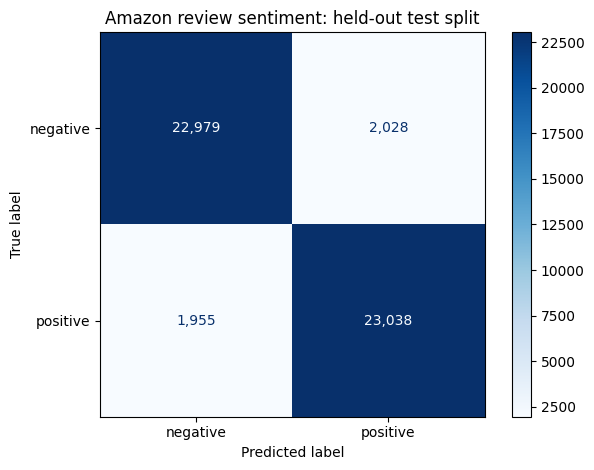

In [21]:
test_started = time.perf_counter()
predictions = model.predict(X_test)
test_inference_seconds = time.perf_counter() - test_started
positive_scores = model.predict_proba(X_test)[:, 1]
print(f'Accuracy: {accuracy_score(y_test, predictions):.4f}')
print(f'F1 (positive class): {f1_score(y_test, predictions):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_test, positive_scores):.4f}')
print(f'Inference latency: {test_inference_seconds / len(X_test) * 1_000_000:.2f} ms per 1,000 reviews')
print(classification_report(y_test, predictions, target_names=['negative', 'positive'], digits=4))
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(cmap='Blues', values_format=',')
plt.title('Amazon review sentiment: held-out test split')
plt.tight_layout()
plt.show()

## 9. Predict sentiment for new reviews

The helper displays the predicted class and estimated positive probability. Interpret the probability as a model score, not a guarantee of correctness.

In [22]:
def analyze_reviews(reviews):
    probabilities = model.predict_proba(reviews)[:, 1]
    labels = model.predict(reviews)
    return pd.DataFrame({
        'review': reviews,
        'predicted_sentiment': ['positive' if label == 1 else 'negative' for label in labels],
        'positive_probability': probabilities,
    })

examples = [
    'The quality is excellent and it arrived earlier than expected.',
    'Stopped working after two days. Very disappointed with this purchase.',
    'It is okay for the price, but I would not buy it again.',
]
display(analyze_reviews(examples))

,review,predicted_sentiment,positive_probability
0,The quality is excellent and it arrived earlier than expected.,positive,0.986223
1,Stopped working after two days. Very disappointed with this purchase.,negative,0.000264
2,"It is okay for the price, but I would not buy it again.",negative,0.004124


## 10. Interpret the linear model with influential n-grams

For logistic regression, coefficient sign indicates the direction of association with positive sentiment, and magnitude indicates strength within the fitted feature space. We plot the 15 strongest positive and negative word or bigram coefficients. These are model associations, not causal explanations. If cross-validation selected a non-linear-probability or non-linear model, this section reports that coefficients are unavailable; the model selector here favors the best CV F1 candidate and all candidates are linear or a dummy baseline, so coefficient support depends on selection.

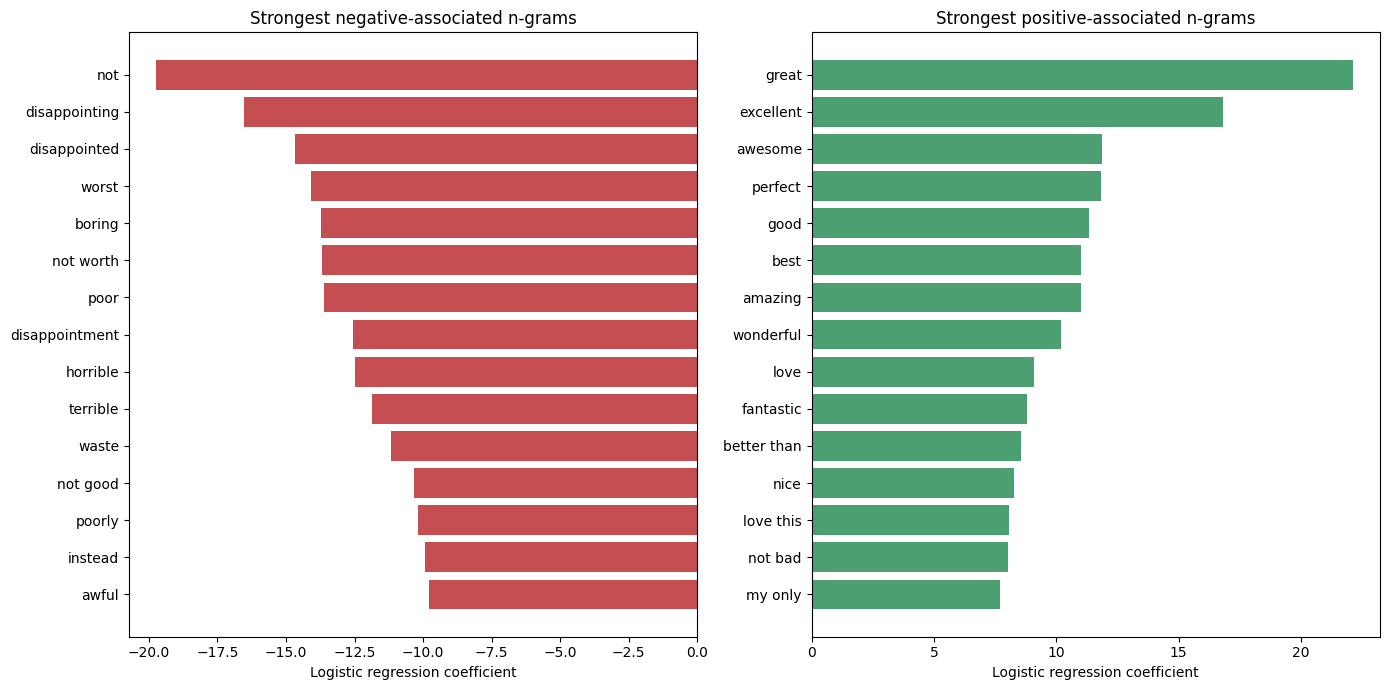

In [23]:
classifier = model.named_steps['classifier']
if hasattr(classifier, 'coef_') and 'tfidf' in model.named_steps:
    feature_names = model.named_steps['tfidf'].get_feature_names_out()
    coefficients = classifier.coef_[0]
    top_negative_idx = coefficients.argsort()[:15]
    top_positive_idx = coefficients.argsort()[-15:][::-1]

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].barh(feature_names[top_negative_idx][::-1], coefficients[top_negative_idx][::-1], color='#c44e52')
    axes[0].set_title('Strongest negative-associated n-grams')
    axes[0].set_xlabel('Logistic regression coefficient')
    axes[1].barh(feature_names[top_positive_idx][::-1], coefficients[top_positive_idx][::-1], color='#4c9f70')
    axes[1].set_title('Strongest positive-associated n-grams')
    axes[1].set_xlabel('Logistic regression coefficient')
    plt.tight_layout()
    plt.show()
else:
    print(f'{selected_model_name} does not expose TF-IDF linear coefficients.')

## 11. Inspect high-confidence errors

We rank mistakes by the model's confidence in its incorrect predicted class, then show up to five false positives and five false negatives. These examples help identify failure modes such as sarcasm, negation, mixed opinions, domain-specific terms, or a title/body mismatch. Review the actual examples before assigning a reason; the labels are rating-derived and can themselves be noisy.

In [24]:
error_analysis = test_sample[['review', 'sentiment']].copy().reset_index(drop=True)
error_analysis['true_label'] = y_test.reset_index(drop=True)
error_analysis['predicted_label'] = predictions
error_analysis['predicted_sentiment'] = error_analysis['predicted_label'].map({0: 'negative', 1: 'positive'})
error_analysis['positive_probability'] = positive_scores
error_analysis['predicted_confidence'] = error_analysis.apply(
    lambda row: row['positive_probability'] if row['predicted_label'] == 1 else 1 - row['positive_probability'], axis=1
)
errors = error_analysis[error_analysis['true_label'] != error_analysis['predicted_label']].copy()
errors['error_type'] = errors.apply(
    lambda row: 'False positive' if row['predicted_label'] == 1 else 'False negative', axis=1
)
for error_type in ['False positive', 'False negative']:
    print(f'\n{error_type}: up to 5 highest-confidence mistakes')
    display(errors[errors['error_type'] == error_type]
            .sort_values('predicted_confidence', ascending=False)
            [['review', 'sentiment', 'predicted_sentiment', 'positive_probability', 'predicted_confidence']]
            .head(5).reset_index(drop=True))


False positive: up to 5 highest-confidence mistakes


,review,sentiment,predicted_sentiment,positive_probability,predicted_confidence
0,"Still the best After using this GPS for several years, I have never had a problem with it. I did note that the professional reviewers were still rating this...",negative,positive,0.999714,0.999714
1,solid An avid ge fan will enjoy this cd. As other reviewers noted D-light is highly underrated as it rocks with typical goldenearring intensity. The lyrics ...,negative,positive,0.998939,0.998939
2,Comic Book the Movie This is a real treat for anyone who loves Comics. The special features alone were worth the movie price. Mark Hamill really gave a hear...,negative,positive,0.998896,0.998896
3,"awesome! this band is truly awesome! my friend tom showed me them because he though the solo was good in one of the songs! WOW! im just blown away, they are...",negative,positive,0.998103,0.998103
4,bw/wm mystery This was an excellent mystery and fine love story. Very interesting and very worth the cost and time.,negative,positive,0.997217,0.997217



False negative: up to 5 highest-confidence mistakes


,review,sentiment,predicted_sentiment,positive_probability,predicted_confidence
0,"bounce in my house this bounce machine is horible, it is not good at all, do not buy it. unless you want to",positive,negative,0.000535,0.999465
1,"Awful!! Bad graphics, movements! Don't waste your money! My husband and I convinced our 12 yr old to spend her hard earned money on this thinking that with ...",positive,negative,0.001268,0.998732
2,Too Over rated What is the point of an little elf to try to save the world. How can a scrony elf destroy so many enemies. It just ain't possible. This game ...,positive,negative,0.002030,0.997970
3,good but i did not get the mp4 in the pick i don't understand why they but a pick that is not whaT THEY send me but the one they send me was not bad at all,positive,negative,0.005711,0.994289
4,You get what you pay for I bought that stupid Elmo seat and it doesn't work. All of the other seats elevate the kid so that the pee (if you have a boy) goes...,positive,negative,0.006184,0.993816


### What the observed errors suggest

In this run, some of the most confident mistakes visibly conflict with their text: enthusiastic reviews appear among negative-labeled examples, while strongly critical reviews appear among positive-labeled examples. That points to rating-derived label noise or review/rating mismatch in addition to familiar NLP challenges such as sarcasm, negation, and mixed opinions. Because the corpus labels come from ratings rather than manual sentiment annotation, these cases should be treated as data-quality signals and checked against the source record before calling them model-only failures.

## 12. Export the trained pipeline

The fitted pipeline contains both TF-IDF preprocessing and the selected classifier. Saving them together prevents training/serving preprocessing mismatches. The artifact is written to the project directory and loaded by the Streamlit demo. Keep large serialized models in release storage or Git LFS if the file size exceeds your repository policy.

In [25]:
artifact_path = Path('sentiment_pipeline.joblib')
joblib.dump({
    'pipeline': model,
    'model_name': selected_model_name,
    'classes': {0: 'negative', 1: 'positive'},
}, artifact_path, compress=3)
print(f'Artifact Saved.')
#print(f'Saved inference artifact: {artifact_path.resolve()} ({artifact_path.stat().st_size / 1024 / 1024:.1f} MB)')

Artifact Saved.


## 13. Summary and limitations

This project compares several transparent text-classification baselines, selects using stratified cross-validation, evaluates once on a held-out split, inspects learned n-grams and difficult examples, and exports a reusable inference pipeline. The benchmark labels come from extreme star ratings (one/two stars negative, four/five stars positive), so mixed and neutral sentiment is outside the task. Results can also reflect dataset era, sampling, and product mix. A production deployment would need monitoring, drift checks, and a representative current validation set.